<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta5_g%C3%B6rev3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: NVIDIA RTX PRO 6000 Blackwell Server Edition


--> İki Yöntem Arasındaki Toplam Hata Değeri (Mutlak Farklar Toplamı): 130450


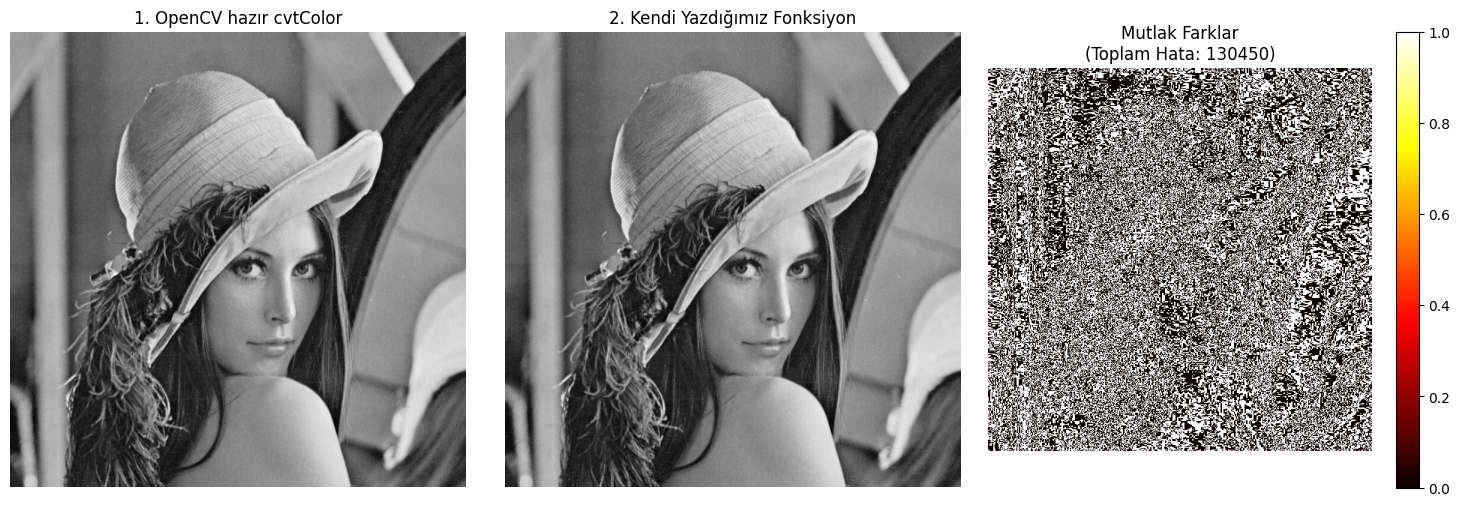

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 1. Test için örnek renkli bir görüntü indirelim (BGR formatında gelir)
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

# -------------------------------------------------------------
# YÖNTEM 1: OpenCV'nin hazır fonksiyonu ile griye dönüştürme
# -------------------------------------------------------------
gray_cv = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# -------------------------------------------------------------
# YÖNTEM 2: Kendi yazdığımız fonksiyon ile griye dönüştürme
# (OpenCV BGR okuduğu için katsayı sırası: B=0.114, G=0.587, R=0.299)
# -------------------------------------------------------------
def custom_grayscale(image):
    # Kanalları ayırıyoruz (Float tipine çevirerek taşmaları önlüyoruz)
    b, g, r = cv2.split(image.astype(np.float32))

    # Standart parlaklık (Luminosity) formülü
    gray = 0.114 * b + 0.587 * g + 0.299 * r

    # 0-255 arasına sınırlandırıp uint8 tipine geri döndürüyoruz
    return np.clip(gray, 0, 255).astype(np.uint8)

gray_custom = custom_grayscale(img)

# -------------------------------------------------------------
# HATA RAPORU: Eşleşen piksellerin mutlak farklarının toplamı (SAD)
# -------------------------------------------------------------
# Veri tiplerini int32 yaparak çıkarma işleminde eksi değer kaybını önlüyoruz
absolute_diff = np.abs(gray_cv.astype(np.int32) - gray_custom.astype(np.int32))
total_error = np.sum(absolute_diff)

print(f"--> İki Yöntem Arasındaki Toplam Hata Değeri (Mutlak Farklar Toplamı): {total_error}")

# -------------------------------------------------------------
# Görselleştirme
# -------------------------------------------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_cv, cmap='gray')
plt.title('1. OpenCV hazır cvtColor')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gray_custom, cmap='gray')
plt.title('2. Kendi Yazdığımız Fonksiyon')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(absolute_diff, cmap='hot')
plt.title(f'Mutlak Farklar\n(Toplam Hata: {total_error})')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()